In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
# readiing the csv file using pandas and converting null values in string format to actual null values
na_vals = ["", " ", "N/A", "NA", "null", "NULL", "none", "-", "?", "unknown"]

df = pd.read_csv("ecommerce_orders.csv", na_values = na_vals)
df.head(7)

,order_id,order_datetime,customer_id,customer_name,email,phone,age,gender,city,state,...,quantity,discount_pct,coupon_code,shipping_fee,total_amount,payment_method,order_status,delivery_date,rating,review_text
0,ORD-2025-000001,2025-01-01 00:33:50,CUST112456,Chaitra Shetty,NaN,+91 7745267611,35.0,Female,Ahmedabad,Gujarat,...,2.0,10.0,NaN,0.0,1481.40,UPI,Delivered,2025-01-05,NaN,NaN
1,ORD-2025-000002,2025-01-01 01:01:41,CUST111640,Shalini Shetty,sshetty81@gmail.com,9838934813,32.0,Female,Bengaluru,Karnataka,...,2.0,0.0,NaN,30.0,88.00,Credit Card,Delivered,2025-01-04,4.0,NaN
2,ORD-2025-000003,2025-01-01 07:04:56,CUST120929,Praveen Nair,praveen.nair@gmail.com,NaN,34.0,NaN,Mangaluru,Karnataka,...,1.0,15.0,FESTIVE15,0.0,6459.15,Net Banking,Delivered,2025-01-04,5.0,NaN
3,ORD-2025-000004,2025-01-01 07:23:39,CUST118403,Mahesh Patil,mahesh.patil@outlook.com,6773807717,39.0,Male,Lucknow,Uttar Pradesh,...,1.0,15.0,FESTIVE15,0.0,2804.15,UPI,Delivered,2025-01-05,NaN,NaN
4,ORD-2025-000005,2025-01-01 08:15:11,CUST105151,Varun Gupta,vgupta486@gmail.com,8216993934,30.0,Male,Bengaluru,Karnataka,...,3.0,0.0,NaN,0.0,4014.00,Credit Card,Delivered,2025-01-05,NaN,NaN
5,ORD-2025-000006,2025-01-01 08:27:43,CUST107933,Rashmi Mukherjee,rmukherjee456@gmail.com,9771172924,18.0,Female,Mangaluru,Karnataka,...,1.0,0.0,NaN,0.0,1842.00,UPI,Delivered,2025-01-08,4.0,NaN
6,ORD-2025-000007,2025-01-01 08:50:26,CUST108874,Kiran Kulkarni,kiran.kulkarni@gmail.com,8552997564,NaN,Male,Hyderabad,Telangana,...,1.0,10.0,NaN,0.0,16586.10,COD,Cancelled,NaN,NaN,NaN


In [4]:
df.dtypes

order_id                str
order_datetime          str
customer_id             str
customer_name           str
email                   str
phone                   str
age                 float64
gender                  str
city                    str
state                   str
pincode             float64
product_id              str
product_name            str
brand                   str
product_category        str
unit_price          float64
quantity            float64
discount_pct        float64
coupon_code             str
shipping_fee        float64
total_amount        float64
payment_method          str
order_status            str
delivery_date           str
rating              float64
review_text             str
dtype: object

In [5]:
# changing dtype of pincode field to string
df["pincode"] = df["pincode"].astype(str)

In [6]:

# changing dtype of columns with date from string to date time
df["order_datetime"] = pd.to_datetime(df["order_datetime"])
df["delivery_date"] = pd.to_datetime(df["delivery_date"])


In [7]:
# replacing null values of fields phone and pincode with actual null values 
df[["phone", "pincode"]] = df[["phone", "pincode"]].replace({"0000000000": np.nan, "000000": np.nan})

In [8]:
df.shape

(80600, 26)

In [9]:
df.describe()

,order_datetime,age,unit_price,quantity,discount_pct,shipping_fee,total_amount,delivery_date,rating
count,80600,70766.000000,79413.00000,79366.000000,76580.000000,77482.000000,79668.000000,73467,35861.000000
mean,2025-12-11 03:16:19.667059,33.545686,3788.89372,1.488459,6.736028,7.662167,4132.248602,2025-12-11 21:35:32.598309,3.564736
min,2025-01-01 00:33:50,-1.000000,27.00000,1.000000,0.000000,0.000000,50.250000,2025-01-02 00:00:00,1.000000
25%,2025-07-05 08:10:00.750000,25.000000,471.00000,1.000000,0.000000,0.000000,567.000000,2025-07-06 00:00:00,3.000000
50%,2025-11-29 16:16:06,32.000000,1102.00000,1.000000,5.000000,0.000000,1274.150000,2025-11-30 00:00:00,4.000000
75%,2026-05-26 13:25:11.250000,38.000000,2495.00000,2.000000,10.000000,0.000000,2719.150000,2026-05-26 00:00:00,5.000000
max,2026-10-31 23:58:21,999.000000,57740.00000,100.000000,25.000000,40.000000,115480.000000,2026-11-07 00:00:00,5.000000
std,NaN,41.719268,8573.79489,2.350230,7.226678,14.775251,8929.603069,NaN,1.354147


In [10]:
df.isnull().any()

order_id            False
order_datetime      False
customer_id         False
customer_name        True
email                True
phone                True
age                  True
gender               True
city                 True
state                True
pincode              True
product_id          False
product_name        False
brand                True
product_category    False
unit_price           True
quantity             True
discount_pct         True
coupon_code          True
shipping_fee         True
total_amount         True
payment_method       True
order_status        False
delivery_date        True
rating               True
review_text          True
dtype: bool

In [11]:
df.isnull().sum()

order_id                0
order_datetime          0
customer_id             0
customer_name        1568
email                5991
phone                6360
age                  9834
gender               5205
city                 3506
state                3356
pincode              7744
product_id              0
product_name            0
brand                2370
product_category        0
unit_price           1187
quantity             1234
discount_pct         4020
coupon_code         56383
shipping_fee         3118
total_amount          932
payment_method       3028
order_status            0
delivery_date        7133
rating              44739
review_text         65722
dtype: int64

In [12]:
# print total number of categorries in gender (i.e. 2) and count of each both gender also incluuding no. of null values 
print(df["gender"].nunique())
df["gender"].value_counts(dropna=False)

2


gender
Male      40580
Female    34815
NaN        5205
Name: count, dtype: int64

In [13]:
# print total number of cities and count of each city also including no. of null values 

print(df["city"].nunique())
print(df["city"].value_counts(dropna=False).head(30))

30
city
Bengaluru     15033
Mumbai         9590
Delhi          9082
Hyderabad      5601
Mangaluru      5580
Chennai        5239
Pune           5154
Kolkata        4237
NaN            3506
Kochi          3450
Mysuru         3132
Ahmedabad      2296
Coimbatore     2070
Udupi          1504
Lucknow        1459
Jaipur         1367
BENGALURU       462
MUMBAI          279
DELHI           270
MANGALURU       187
CHENNAI         180
PUNE            163
HYDERABAD       152
KOCHI           125
KOLKATA          97
MYSURU           92
COIMBATORE       74
AHMEDABAD        71
LUCKNOW          56
UDUPI            50
Name: count, dtype: int64


In [14]:
# print total number of product categories and count of each category

print(df["product_category"].nunique())
print(df["product_category"].value_counts(dropna=False))

14
product_category
Clothing                  18992
Electronics               15134
Grocery                   14217
Home & Kitchen            11230
Beauty & Personal Care     8742
Books                      6332
Sports & Fitness           4743
clothing                    275
electronics                 240
grocery                     215
home & kitchen              167
beauty & personal care      131
books                        97
sports & fitness             85
Name: count, dtype: int64


In [15]:
# number of states and count of each state
print(df["state"].nunique())
print(df["state"].value_counts(dropna=False))

10
state
Karnataka        26079
Maharashtra      15286
Delhi             9347
Tamil Nadu        7573
Telangana         5756
West Bengal       4299
Kerala            3592
NaN               3356
Gujarat           2380
Uttar Pradesh     1526
Rajasthan         1406
Name: count, dtype: int64


In [16]:
# no. of duplicate records
print(df.duplicated().sum())

600


In [17]:
# range of age of customers
print(df["age"].min())
print(df["age"].max())

-1.0
999.0


In [18]:
# range of order date
print(df["order_datetime"].min())
print(df["order_datetime"].max())

2025-01-01 00:33:50
2026-10-31 23:58:21


In [19]:
# range of quantity
print(df["quantity"].min())
print(df["quantity"].max())

1.0
100.0


In [20]:
# remove duplicate records
print("before", len(df))
df = df.drop_duplicates().copy()
print("after", len(df))


before 80600
after 80000


In [21]:
# change the city name and product category to tittle format since some city name appear in lowercase and uppercase which may result in considering 2 diffrent city
df["city"] = df["city"].str.title()
df["product_category"] = df["product_category"].str.title()

In [22]:
# changing the dtypes of categorical type field from str to category
for col in ["gender", "city", "state", "product_category", "payment_method", "order_status", "brand"]:
    df[col] = df[col].astype("category")

In [23]:
df.dtypes

order_id                       str
order_datetime      datetime64[us]
customer_id                    str
customer_name                  str
email                          str
phone                          str
age                        float64
gender                    category
city                      category
state                     category
pincode                        str
product_id                     str
product_name                   str
brand                     category
product_category          category
unit_price                 float64
quantity                   float64
discount_pct               float64
coupon_code                    str
shipping_fee               float64
total_amount               float64
payment_method            category
order_status              category
delivery_date       datetime64[us]
rating                     float64
review_text                    str
dtype: object

In [24]:
# set invalid age and quantity to null
df.loc[~df["age"].between(18, 80), "age"] = np.nan
df.loc[df["quantity"] > 10, "quantity"] = np.nan

In [25]:
# field with month and year
df["year_month"]  = df["order_datetime"].dt.to_period("M").astype(str)


In [26]:
# creatingg a new field for no. of days taken for delivery
df["delivery_days"] = (df["delivery_date"] - df["order_datetime"].dt.normalize()).dt.days


In [27]:
# dropping unnecessasary columns
df = df.drop(columns=["phone", "email", "pincode", "customer_name", "review_text"])

In [28]:
# shae after drop
df.shape

(80000, 23)

In [29]:
df.head()

,order_id,order_datetime,customer_id,age,gender,city,state,product_id,product_name,brand,...,discount_pct,coupon_code,shipping_fee,total_amount,payment_method,order_status,delivery_date,rating,year_month,delivery_days
0,ORD-2025-000001,2025-01-01 00:33:50,CUST112456,35.0,Female,Ahmedabad,Gujarat,P1008,Logitech M221 Wireless Mouse,Logitech,...,10.0,NaN,0.0,1481.40,UPI,Delivered,2025-01-05,NaN,2025-01,4.0
1,ORD-2025-000002,2025-01-01 01:01:41,CUST111640,32.0,Female,Bengaluru,Karnataka,P1061,Tata Salt 1kg,Tata,...,0.0,NaN,30.0,88.00,Credit Card,Delivered,2025-01-04,4.0,2025-01,3.0
2,ORD-2025-000003,2025-01-01 07:04:56,CUST120929,34.0,NaN,Mangaluru,Karnataka,P1028,Raymond Wool Blazer,Raymond,...,15.0,FESTIVE15,0.0,6459.15,Net Banking,Delivered,2025-01-04,5.0,2025-01,3.0
3,ORD-2025-000004,2025-01-01 07:23:39,CUST118403,39.0,Male,Lucknow,Uttar Pradesh,P1052,Bajaj Rapid Mixer Grinder 750W,Bajaj,...,15.0,FESTIVE15,0.0,2804.15,UPI,Delivered,2025-01-05,NaN,2025-01,4.0
4,ORD-2025-000005,2025-01-01 08:15:11,CUST105151,30.0,Male,Bengaluru,Karnataka,P1040,Cracking the Coding Interview,CareerCup,...,0.0,NaN,0.0,4014.00,Credit Card,Delivered,2025-01-05,NaN,2025-01,4.0


In [30]:
# creating a report on null values in the df
null_count = df.isnull().sum()
null_percentage = (null_count / len(df) * 100).round(2)
null_report = pd.DataFrame({"null_count": null_count, "null_percentage": null_percentage})
null_report = null_report[null_report["null_count"]>0]
null_report

,null_count,null_percentage
age,10175,12.72
gender,5153,6.44
city,3480,4.35
state,3319,4.15
brand,2351,2.94
unit_price,1178,1.47
quantity,1285,1.61
discount_pct,3998,5.00
coupon_code,55977,69.97
shipping_fee,3092,3.86


In [31]:
import matplotlib.pyplot as plt

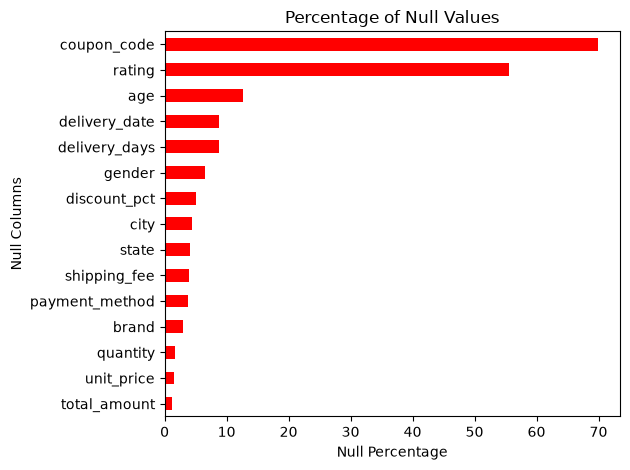

In [32]:
# horizontal bar graph to vizualize null report
null_report["null_percentage"].sort_values().plot(kind="barh", color="red")
plt.title("Percentage of Null Values")
plt.xlabel("Null Percentage")
plt.ylabel("Null Columns")
plt.tight_layout()
plt.show()

In [33]:
# mean imputatiion for columns with nuumerical values
num_cols = ["age", "unit_price", "quantity", "discount_pct", "shipping_fee", "total_amount"]

for col in num_cols:
    mean_val = df[col].mean()
    df[col] = df[col].fillna(mean_val)
    print(f"{col:14s} mean used = {mean_val:.2f}")

age            mean used = 31.97
unit_price     mean used = 3790.81
quantity       mean used = 1.43
discount_pct   mean used = 6.73
shipping_fee   mean used = 7.66
total_amount   mean used = 4132.88


In [34]:
# rounding of age and quantity field to whole number after filling null to mean values 
df["age"] = df["age"].round().astype(int)
df["quantity"] = df["quantity"].round().astype(int)

In [35]:
# creating rating filled column with mean imputation 
df["rating_filled"] = df["rating"].fillna(df["rating"].mean())

In [36]:
# fill null values in required categoty type field with unknown
for col in ["gender", "city", "state", "payment_method", "brand"]:
    df[col] = df[col].cat.add_categories("Unknown").fillna("Unknown")

print("Nulls left in numeric columns:", df[num_cols].isna().sum().sum())
df.isna().sum()[lambda s: s > 0]

Nulls left in numeric columns: 0


coupon_code      55977
delivery_date     7072
rating           44390
delivery_days     7072
dtype: int64

In [37]:
# creating a new df with only orders that are valid(removing cancelled and returned products)
valid = df[~df["order_status"].isin(["Cancelled", "Returned"])].copy()
print("Valid orders:", len(valid), "of", len(df))
print("Total revenue: Rs", f"{valid['total_amount'].sum():,.0f}")
print("Average order value: Rs", f"{valid['total_amount'].mean():,.0f}")

Valid orders: 67311 of 80000
Total revenue: Rs 279,413,025
Average order value: Rs 4,151


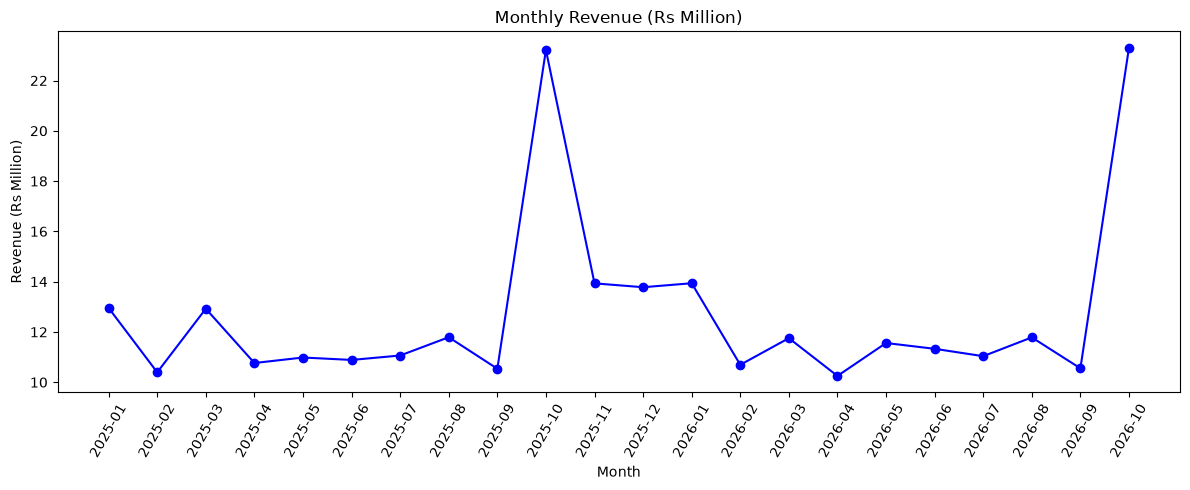

year_month
2026-10    23.30
2025-10    23.21
2026-01    13.94
Name: total_amount, dtype: float64


In [38]:
# graph to vizualize monthly revenue
monthly = valid.groupby("year_month")["total_amount"].sum() / 1e6

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="blue")
plt.title("Monthly Revenue (Rs Million)")
plt.xlabel("Month"); plt.ylabel("Revenue (Rs Million)")
plt.xticks(rotation=60)
plt.tight_layout(); plt.show()

print(monthly.round(2).sort_values(ascending=False).head(3))

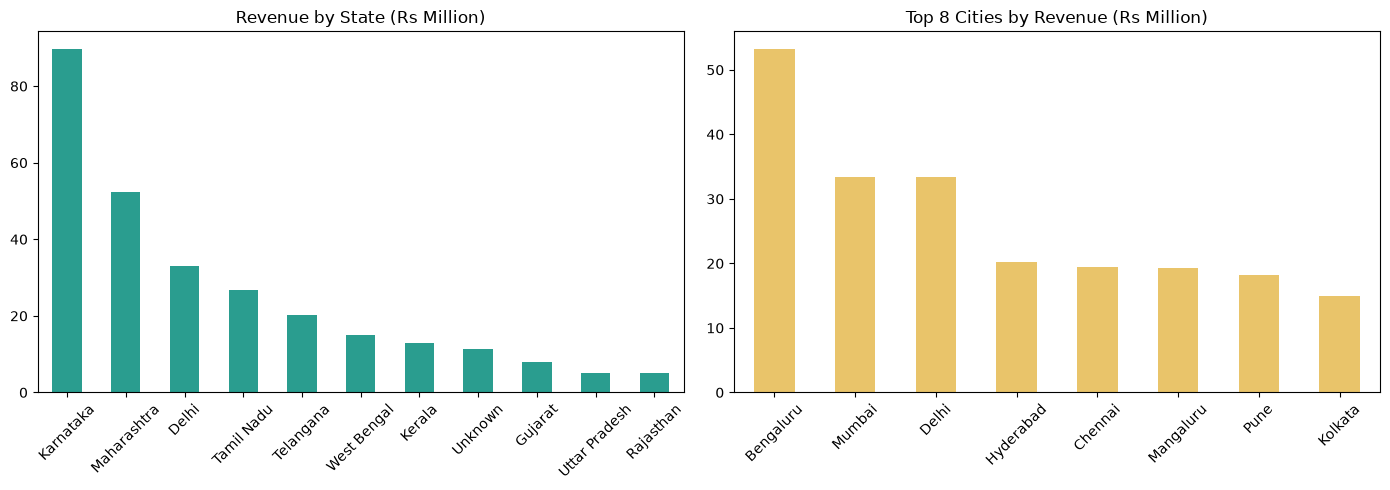

In [39]:
# state wise and city wise graph
state_rev = valid.groupby("state", observed=True)["total_amount"].sum().sort_values(ascending=False) / 1e6
city_rev  = valid.groupby("city", observed=True)["total_amount"].sum().sort_values(ascending=False).head(8) / 1e6

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
state_rev.plot(kind="bar", ax=ax[0], color="#2a9d8f"); ax[0].set_title("Revenue by State (Rs Million)")
city_rev.plot(kind="bar", ax=ax[1], color="#e9c46a");  ax[1].set_title("Top 8 Cities by Revenue (Rs Million)")
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [40]:
import seaborn as sns

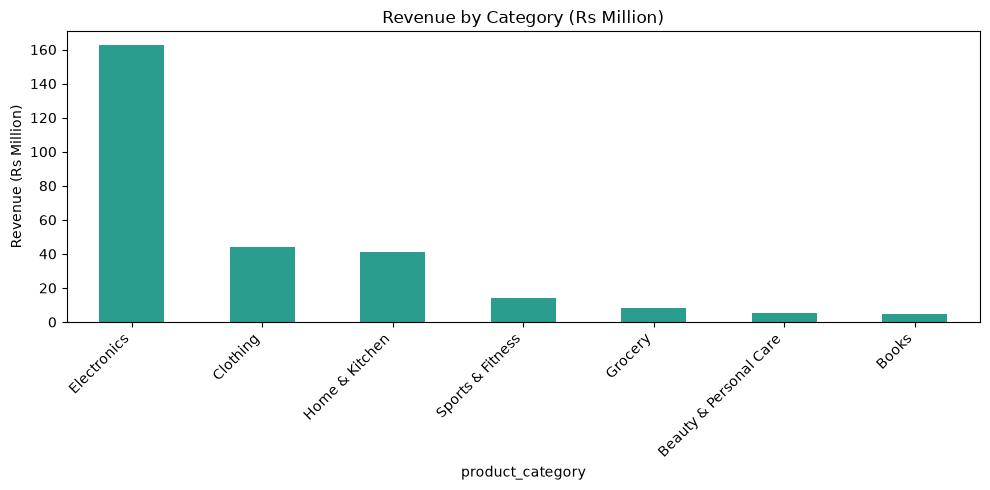

In [41]:
# cattegory wise revenue
cat_rev = valid.groupby("product_category", observed=True)["total_amount"].sum().sort_values(ascending=False) / 1e6
cat_rev.plot(kind="bar", color="#2a9d8f", figsize=(10, 5))

plt.title("Revenue by Category (Rs Million)")
plt.ylabel("Revenue (Rs Million)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

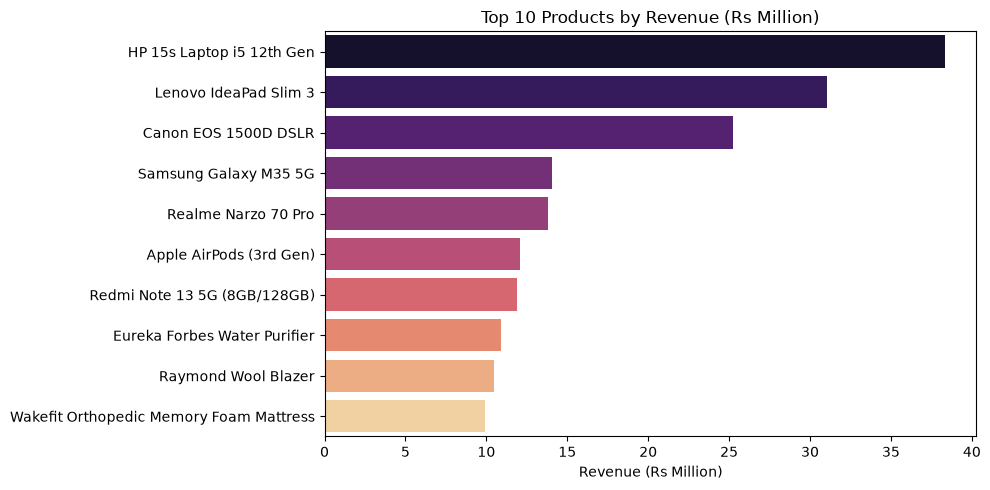

In [42]:
# revenue by products
top_products = valid.groupby("product_name")["total_amount"].sum().sort_values(ascending=False).head(10) / 1e6

plt.figure(figsize=(10, 5))
sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index, palette="magma", legend=False)
plt.title("Top 10 Products by Revenue (Rs Million)")
plt.xlabel("Revenue (Rs Million)"); plt.ylabel("")
plt.tight_layout(); plt.show()

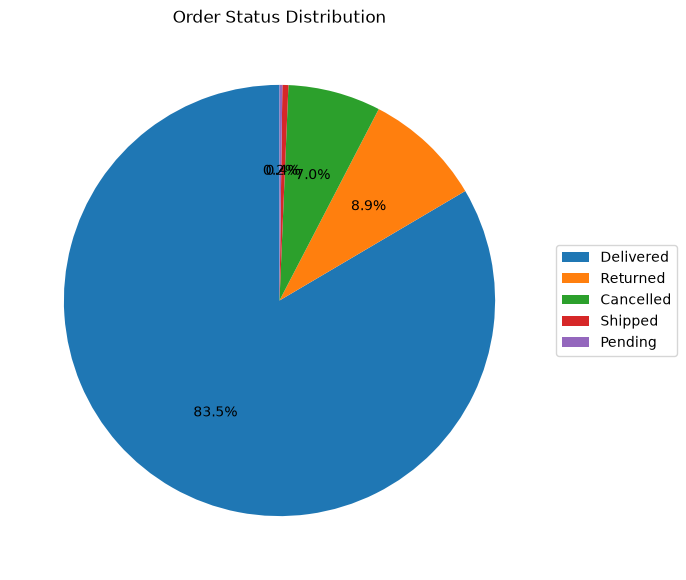

In [43]:
# pie chart for order status
status_share = df["order_status"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(status_share, autopct="%1.1f%%", startangle=90)
plt.legend(status_share.index, loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Order Status Distribution")
plt.show()

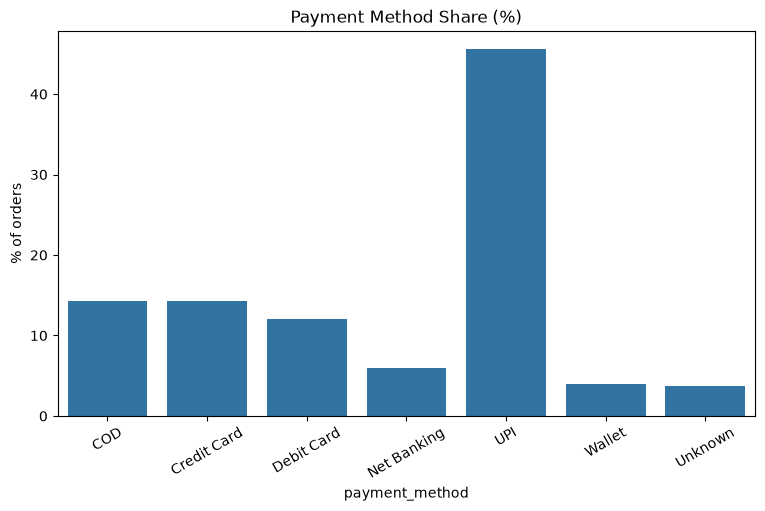

In [44]:
# graph for payment method
pay_share = df["payment_method"].value_counts() / len(df) * 100

plt.figure(figsize=(9, 5))
sns.barplot(x=pay_share.index, y=pay_share.values)
plt.title("Payment Method Share (%)")
plt.ylabel("% of orders")
plt.xticks(rotation=30)
plt.show()